# **Járműkommunikációs forgalom- és torlódás-monitorozás labor megoldókulcsa**
Ebben a feladatsorban valós járműkommunikációs (V2X) üzenetlogokból dolgozunk: Modena belvárosában egy Road Side Unit (RSU) rögzítette a közelében elhaladó autók által szétsugárzott CAM és DENM üzeneteket. A feladat során megismerhető, hogy mik a célja ezen üzeneteknek, illetve hogyan épülnek fel ezek, majd pár feladat segítségével egy kisebb betekintést lehet nyerni a V2X világába.

## **Járműkommunikációs alapok a labor megértéséhez**

### **Alapgondolatok**

A V2X lényege, hogy a napjainkban előforduló baleseteket, illetve a környezetszennyezést csökkentse. Ha önvezető járműre gondolunk, akkor eszünkbe juthat a Tesla. Az ő gondolkodásmenetük azonban kizárja a V2X használatát, mivel úgy látják, egy önvezető autónak úgy kell funkcionálnia, mintha ember vezetné. Vannak viszont helyzetek, ahol ez már nem elég: például egy beláthatatlan kereszteződésnél a szenzorok nem látják a közeledő másik autót. A V2X (ebben az esetben a V2V – Vehicle to Vehicle) ezt (sok más use-case mellett) a járművek közötti kommunikációval küszöböli ki.

### **Üzenetek**

> **CAM** (Cooperative Awareness Message): az autók „életjele". Ezt küldi a környezetében lévő autóknak és útmenti egységeknek, hogy tudják a pozícióját, sebességét, haladási irányát.

> **DENM** (Decentralized Environmental Notification Message): „különleges" üzenet – például ha egy autó megáll, csúszik, vagyis a normális haladástól eltérő eseményt jelez.

### **Egyéb információk**

Hálózati szempontból érdekes, hogyan oldják meg a mérnökök, hogy ne legyen torlódás a csatornán. Ahogy a V2X fejlődik, egyre több adatot fognak közölni egymással a járművek (pl. szenzoradatokat is megosztanak). Fontos, hogy ezek ne „üssék ki" a biztonságkritikus üzeneteket, mint a CAM és a DENM – ezért ezek külön csatornán mennek: a szenzoradatok például az **SCH1**-en, a CAM és a DENM a **CCH**-n.

Az alábbi feladatokkal betekintést nyerhetünk abba, hogyan van szabályozva a forgalom a csatornán, és hogyan lehet valós adatból a terhelést és a forgalmi állapotot monitorozni.

## **0. Feladat – Adatok betöltése**

### **Röviden az adathalmazról**

A CAMASA adathalmazt a Modenai Egyetem kutatói készítették a MASA (Modena Automotive Smart Area) élő tesztkörnyezetben: 18 db Road Side Unit (RSU) fedi le a város egy ~0,64 km²-es részét, és rögzítik a közelükben elhaladó, gyári V2X-csomaggal felszerelt autók CAM és DENM üzeneteit. A teljes adathalmaz 40 millió feletti CAM-ot tartalmaz, nyers PCAP-fájlokból feldolgozva.

Ez ugye számunkra túl nagy lenne, így 1 RSU 10 pcap fileját dolgoztam fel, ezt a szerzők hivatalos scriptjeivel tettem meg, amelyet a github repóm dokumentációja alatt érhetnek el az emberek.

A teljes adathalmazról és a szkriptről itt lehet olvasni:
https://www.automotivesmartarea.it/dataset/

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/jade1212/V2X-Sim-Lab/resolve/main/camasa_student_sample.csv"
df_raw = pd.read_csv(url)
display(df_raw.head())

,timestamp,source_address,stationID,Longitude,Latitude,Heading,Speed,generationDeltaTime,rsu_ip,source_file,messageID,originatingStationID,causeCode,subCauseCode
0,2025-04-19T10:07:45.156614000Z,4e:36:f2:de:9f:09,4074675977,109346718,446547572,10.0,1107.0,4544.0,192.168.12.120,gn_2025-04-19_attached_parsed.json,NaN,NaN,NaN,NaN
1,2025-04-19T10:07:45.559037000Z,4e:36:f2:de:9f:09,4074675977,109346727,446547965,6.0,1074.0,4943.0,192.168.12.120,gn_2025-04-19_attached_parsed.json,NaN,NaN,NaN,NaN
2,2025-04-19T10:07:46.452965000Z,4e:36:f2:de:9f:09,4074675977,109346734,446548738,0.0,917.0,5823.0,192.168.12.120,gn_2025-04-19_attached_parsed.json,NaN,NaN,NaN,NaN
3,2025-04-19T10:07:46.656707000Z,4e:36:f2:de:9f:09,4074675977,109346735,446548933,3598.0,880.0,6057.0,192.168.12.120,gn_2025-04-19_attached_parsed.json,NaN,NaN,NaN,NaN
4,2025-04-19T10:07:46.853314000Z,4e:36:f2:de:9f:09,4074675977,109346736,446549090,3598.0,863.0,6265.0,192.168.12.120,gn_2025-04-19_attached_parsed.json,NaN,NaN,NaN,NaN


Ha nem sikerülne betölteni, a githubon található csv-t töltsétek fel a mappába, és futtassátok az alábbi cellát:


In [2]:
#Backup ha nem működött volna az előző cella:

df_raw = pd.read_csv("camasa_student_sample.csv")
display(df_raw.head())

FileNotFoundError: [Errno 2] No such file or directory: 'camasa_student_sample.csv'

##**1. Feladat - Ismerkedés az adatokkal**

### **A paraméterek értelmezése**

> **timestamp**: az útmenti egység által rögzített vételi idő (UTC)

> **source_address**: a küldő hálózati (GeoNetworking/MAC) címe

> **stationID**: az ETSI szerinti állomásazonosító (álnév)

> **Longitude, Latitude**: pozíció (pl. `446547572` = 44,6547572°)

> **Heading**: haladási irány  (`3598` = 359,8°); a `3601` jelentése: „nem elérhető"

> **Speed**: (`1107` = 11,07 m/s ); a `16383` jelentése: „nem elérhető"

> **generationDeltaTime**: a **küldő autó** saját órája szerinti generálási idő [ms], 0–65535 között – 65536 ms-onként körbefordul

> **rsu_ip, source_file**: melyik útmenti egység, melyik feldolgozott napi fájl az eredet

> **messageID, originatingStationID, causeCode, subCauseCode**: a DENM-ek mezői; CAM-sorokban üresek (`NaN`)

Láthatjuk, hogy milyen sok nagyszerű adatunk van, azonban van olyan, amely ebben a feladatsorban szükségtelen. Már az elején említettem, hogy egy borzalmasan nagy adathalmazt nyírtam le kisebbre, így 1 RSU adatait használtam csak.

Ezeken felül, megismerhettük a különbséget a két üzenet között. Mit gondolunk így előre, melyikből lehet több átlagosan?

###**Feladat:**
>**A)** Szűrd le azon oszlopokat, amelyek a feladat szempontjából redundánsak.

>**B)** Listázd ki a CAM és DENM üzenetek számosságát - meglep az eredmény?

>**C)** Milyen különböző DENM üzenetek találhatóak az adathalmazban?

In [44]:
#TODO: Dimenziócsökkentés (redundáns oszlopok kiszedése)
df = df_raw.drop(columns=["rsu_ip","source_file"])

display(df.head())

,timestamp,source_address,stationID,Longitude,Latitude,Heading,Speed,generationDeltaTime,messageID,originatingStationID,causeCode,subCauseCode
0,2025-04-19T10:07:45.156614000Z,4e:36:f2:de:9f:09,4074675977,109346718,446547572,10.0,1107.0,4544.0,NaN,NaN,NaN,NaN
1,2025-04-19T10:07:45.559037000Z,4e:36:f2:de:9f:09,4074675977,109346727,446547965,6.0,1074.0,4943.0,NaN,NaN,NaN,NaN
2,2025-04-19T10:07:46.452965000Z,4e:36:f2:de:9f:09,4074675977,109346734,446548738,0.0,917.0,5823.0,NaN,NaN,NaN,NaN
3,2025-04-19T10:07:46.656707000Z,4e:36:f2:de:9f:09,4074675977,109346735,446548933,3598.0,880.0,6057.0,NaN,NaN,NaN,NaN
4,2025-04-19T10:07:46.853314000Z,4e:36:f2:de:9f:09,4074675977,109346736,446549090,3598.0,863.0,6265.0,NaN,NaN,NaN,NaN


In [45]:
#TODO: hány DENM és CAM üzenet található a DataFramben
denm_counts = len(df[df["causeCode"].notna()])
cam_counts = len(df) - denm_counts

print("DENM számossága: ",denm_counts)
print("CAM számossága: ",cam_counts)

DENM számossága:  18
CAM számossága:  14700


Ez azért annyira nem meglepő, életjelet természetesen többször fog adni a jármű mint "különleges" üzenetet.

In [73]:
#TODO: milyen DENM üzenetek vannak az adathalmazban
# causeCode subCauseCode szerint érdemes csoportosítani
denm = df[df["causeCode"].notna()].copy().groupby(["causeCode","subCauseCode"])


display(denm.agg(db=("stationID", "count"),
        kulonbozo_auto=("stationID", "nunique")
        ).sort_values("db",ascending = False)
)



,,db,kulonbozo_auto
causeCode,subCauseCode,,
1.0,1.0,18,5


> Az 1-es Code jelentése: Növekvő forgalmi torlódás / Traffic Increasing

A kis szeletünkbe csak ilyen került bele, azonban az adathalmazban, illetve a valóságban is használnak többet a járművek.

### **Feladat – Mértékegységek és „nem elérhető" értékek**

Az elején láthattuk, hogy egyes adatok eléggé furán vannak tárolva, illetve vannak olyan esetek amikor helytelen értékek vannak tárolva = "nem elérhetőek". Ezeket hozzuk rendbe, az utóbbi eseteket cseréljük NaN-ra.

>**Szorgalmi:** Javítsd ki a helytelen adatokat, értelmezhetővé.

Ha valakinek van kedve, akkor fentebb leírtam, mik, hogy vannak tárolva (és alább van egy tutorial is, hogy kb mit kell csinálni), azonban én bennehagyom a kódot, hogy egyszerűen javítani lehessen a hibákat, hisz nem ez a labor lényege.


1. `timestamp` → valódi időbélyeg (`pd.to_datetime(..., utc=True)`), majd rendezd időrendbe.
2. `lat`, `lon` = `Latitude`, `Longitude` osztva `1e7`-tel
3. `speed_ms` = `Speed` / 100 – **de előbb** a `16383` („nem elérhető") értéket cseréld `NaN`-ra
4. `heading_deg` = `Heading` / 10 – **de előbb** a `3601` („nem elérhető") értéket cseréld `NaN`-ra
5. `rel_time`: másodperc az első üzenettől (`float`)
6. Dobd el a nyers `Latitude`, `Longitude`, `Speed`, `Heading` oszlopokat

>**Súgó**: `Series.where(feltétel)` megtartja az igaz értékeket, a többit `NaN`-ra cseréli.

In [31]:
#Szorgalmi TODO:
#Ez alatti cellát futtatva, ugyanazt az eredményt kell kapjuk


#df["timestamp"] = ...
#df = ...

#df["lat"] =...
#df["lon"] =  ...
#df["speed_ms"] = ...
#df["heading_deg"] = ...
#df["rel_time"] = ...

#df = ...

In [46]:
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df = df.sort_values("timestamp").reset_index(drop=True)

df["lat"] = df["Latitude"] / 1e7
df["lon"] = df["Longitude"] / 1e7
df["speed_ms"] = df["Speed"].where(df["Speed"] != 16383) / 100
df["heading_deg"] = df["Heading"].where(df["Heading"] != 3601) / 10
df["rel_time"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds()

df = df.drop(columns=["Latitude", "Longitude", "Speed", "Heading"])

### **Feladat – Mikor és meddig mértünk**

A 10 PCAP-fájl nem feltétlenül követi egymást hézag nélkül. Ha két rögzítés között kimaradt idő, ha ezt nullás üzenetszámként számoljuk, az átlagok hibásak lesznek. Ezeket fogjuk most fixelni:

- az adat időtartama UTC-ben és helyi időben van alapból
- a legnagyobb időközök két egymást követő üzenet között
- egy `valid_sec` maszk: azok a másodpercek, amelyek nincsenek egy `GAP_S` másodpercnél hosszabb résben

In [47]:
GAP_S = 300     #Ezzel lehet játszadozni. Ennél hosszabb csendet, már rögzített résnek tekintjük
                #ha van kedv, próbáljátok ki mondjuk 60 vagy 600-al is a feladatsort

#Hogy ne karakterisztikus adat legyen hanem szám
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, format="ISO8601")

#TODO: Sortold a dataframet, és a rel_time, legyen a timestamp és az első rögzítés közti különbség
#segítség: .dt.total_seconds() fgv. segíthet a váltásban
df = df.sort_values("timestamp")
df["rel_time"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds()

#TODO: első és utolsó rögzítési adatok
t0_utc, t1_utc = df["timestamp"].iloc[0], df["timestamp"].iloc[-1]

print("Időtartam (UTC):  ", t0_utc, "->", t1_utc)


gaps = df["rel_time"].diff()

print("\nLegnagyobb időközök két egymást követő üzenet között:")
display(pd.DataFrame({"rés [s]": gaps.nlargest(5).round(1),
                      "a rés után (helyi idő)": df.loc[gaps.nlargest(5).index, "timestamp"].dt.tz_convert("Europe/Rome").dt.strftime("%H:%M:%S")}))


T = int(np.ceil(df["rel_time"].iloc[-1])) + 1  # az adat hossza másodpercben
valid_sec = np.ones(T, dtype=bool)
for i in np.where(gaps > GAP_S)[0]:
    valid_sec[int(np.ceil(df["rel_time"].iloc[i - 1])): int(np.floor(df["rel_time"].iloc[i]))] = False
print(f"\n{T} másodpercből {int(valid_sec.sum())} érvényes ({(~valid_sec).sum()} s hiányzó mérés, GAP_S = {GAP_S}).")

Időtartam (UTC):   2025-04-19 10:07:45.156614+00:00 -> 2025-04-29 04:41:09.286416+00:00

Legnagyobb időközök két egymást követő üzenet között:


,rés [s],a rés után (helyi idő)
8472,234404.5,09:53:10
2085,89048.2,00:34:48
4003,75305.3,07:46:06
10754,35094.2,11:51:52
14577,33991.9,06:39:47



844406 másodpercből 10134 érvényes (834272 s hiányzó mérés, GAP_S = 300).


## **2. Feladat – Forgalom áttekintése**


**A) Átlagos üzenet/s**

Csinálj 1 másodpercenként bin-eket, mégpedig úgy, hogy lemásolod a DataFrameben található CAM üzenetek sorait (copy), és a másolatban létrehozol egy új oszlopot, "sec_bin" néven. Ezután az adatok kiírásánal végezd el a hátralévő feladatot, a mezőneveknek megfelelően.
>**Súgó**: a rel_timeokat érdemes úgy integerekké alakítani, hogy lefele kerekíted őket, ezzel egyszerűen el tudod végezni a binninget.

>**FONTOS**: a másodperc, amelyben nem jött üzenet, a `value_counts()`-ban egyszerűen nem szerepel – az átlag így felfelé torzulna. Pótold a hiányzó másodperceket **0-val** (`reindex(range(T), fill_value=0)`), majd csak az **érvényes** másodperceket tartsd meg (`valid_sec`).


In [48]:
#Csak CAM üzenetekkel dolgozunk itt:

cam = df[df['causeCode'].isna()].copy() #TODO: szűrd ki a CAM üzeneteket

cam["sec_bin"] = np.floor(cam["rel_time"]) #hozz létre másodpercenkénti bin-eket

msg_per_sec = cam["sec_bin"].value_counts().reindex(range(T), fill_value=0)
msg_per_sec = msg_per_sec[valid_sec]

rate_stats = pd.Series({
    "átlagos CAM/s": msg_per_sec.mean(), #TODO
    "max CAM/s": msg_per_sec.max(), #TODO
    "szórás": msg_per_sec.std(), #TODO
    "üres másodpercek aránya": (msg_per_sec == 0).mean(), #nem érkezett az RSU-hoz üzenet
})
display(rate_stats.round(3))

,0
átlagos CAM/s,1.451
max CAM/s,10.000
szórás,1.465
üres másodpercek aránya,0.345


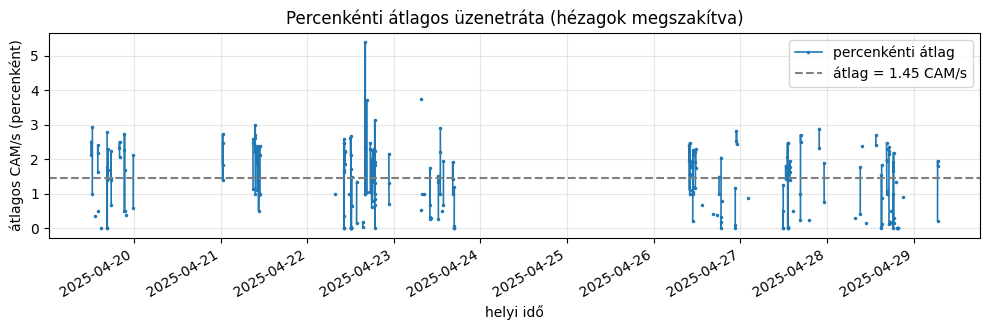

In [49]:
#Ábrázolás (ez magától is működik, nem kell módosítani)
#A hézagok azért vannak benne, hogy megszakadjon a rács amikor nincs adat

t0_local = t0_utc.tz_convert("Europe/Rome").tz_localize(None)

# Csak az érvényes másodpercekhez tartozó sorok (feltételezve, hogy msg_per_sec indexe 0..T-1)
valid_secs_idx = msg_per_sec.index[msg_per_sec > 0]
sec_times_local = t0_local + pd.to_timedelta(msg_per_sec.index, unit="s")

s_sec = pd.Series(msg_per_sec.values, index=sec_times_local)
s_min = s_sec.resample("1min").mean()

# Teljes perces rács -> ahol nincs adat (hézag), ott NaN marad, így megszakad a vonal
full_min_idx = pd.date_range(
    start=s_min.index.min().floor("1min"),
    end=s_min.index.max().ceil("1min"),
    freq="1min",
)
s_min_plot = s_min.reindex(full_min_idx)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(
    s_min_plot.index,
    s_min_plot.values,
    marker=".",
    ms=3,
    lw=1.2,
    label="percenkénti átlag",
)
ax.axhline(
    msg_per_sec.mean(),
    color="gray",
    ls="--",
    label=f"átlag = {msg_per_sec.mean():.2f} CAM/s",
)
ax.set_xlabel("helyi idő")
ax.set_ylabel("átlagos CAM/s (percenként)")
ax.set_title("Percenkénti átlagos üzenetráta")
ax.legend()
ax.grid(True, alpha=0.3)
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()

Itt lehet látni, hogy van amikor egyáltalán nincsenek autók a közelben, sokszor pedig igen gyakran küldözgetnek egymásnak üzeneteket.

###**A szabvány egy fontos eleme**

Tegyük fel magunknak a kérdést:

>*Egy dugóban ülve 5 perce, 0 métert mozdulva, érdekel engem hogy ugyanaz a Skoda Fabia csücsül mögöttem, avagy sem?*

Természetesen ha egy több száz járműves dugóban, mindenki folyamatosan küldözgetné az üzenetét, hogy ő hol van, akkor elég hamar túlterhelt lenne a csatorna redundáns információval, ezért van az, hogy a ETSI CAM szabványa meghatározza a küldésidőt:
> Minimum: 1Hz, vagyis másodpercenként 1 üzenet

> Maximum: 10Hz, vagyis másodpercenként 10 üzenet

Így már láthatjuk, hogy egy ilyen dugóban általában másodpercenként 1 üzenetet fogunk kapni.

Az ETSI CAM szabványa az alábbi feltételek alapján generál a jármű újabb CAM-ot:
> több, mint 4 métert mozgott a jármű

> több, mint 0.5 m/s-al megváltozott a jármű haladási sebessége

> több, mint 4°-kal változott a haladási irány

> több, mint 1 másodperc eltelt az előző CAM üzenete között


**B) Feltételek teljesülése**

Vizsgáljuk meg, mely feltétel teljesül a leggyakrabban a fentiek közül.

Rövid vázlat:

> Készíts egy másolatot rx néven, a cam adathalmazról, sortolva a stationID és timestamp-re

>Hozz létre stationID-ként csoportokat (hogy egyes járművek külön vizsgálhatóak legyenek)

>Számold ki az új mezőket, amelyek megadják a különbségeket az egyes feltételek szempontjából

>Fogalmazd meg a 4 feltételt, és nézd meg a diagrammon, hogyan oszlanak el az egyes eredmények

In [74]:
rx = cam.sort_values(["stationID", "timestamp"]).copy()

g = rx.groupby("stationID")

rx["dt"] = (g["generationDeltaTime"].diff() % 65536) / 1000.0
rx["dt_rx"] = g["timestamp"].diff().dt.total_seconds()
rx["spd_prev"] = g["speed_ms"].shift(1)
rx["dist"] = np.hypot(
    g["lon"].diff() * 111320 * np.cos(np.radians(rx["lat"])),
    g["lat"].diff() * 110574,
)
rx["dspd"] = g["speed_ms"].diff().abs()
d_head = g["heading_deg"].diff()
rx["dhead"] = ((d_head + 180) % 360 - 180).abs()

valid = rx[
    (rx["dt"] > 0) & (rx["dt"] <= 1.05) & ((rx["dt"] - rx["dt_rx"]).abs() < 0.5)
].copy()

# A 4 ETSI feltétel röviden:
etsi_trigger = (
    (valid["dist"] > 4.0)
    | (valid["dspd"] > 0.5)
    | (valid["dhead"] > 4.0)
    | (valid["dt"] >= 0.95)
)

### **EXTRA FELADAT - Szerencsejáték**
Tippeld meg, hogy melyik feltétel/trigger jelenik meg legtöbbször:

In [ ]:
#Lehetséges opciók: "dist", "spd", "dir", "tmr"
tipp = "spd"

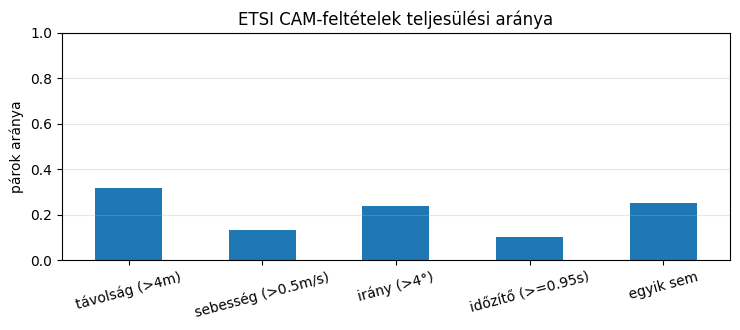

In [51]:
#Ábrázolás (nem kell beleírni)


# milyen arányban teljesülnek az egyes feltételek vs. egyik sem
shares = pd.Series({
    "távolság (>4m)": (valid["dist"] > 4.0).mean(),
    "sebesség (>0.5m/s)": (valid["dspd"] > 0.5).mean(),
    "irány (>4°)": (valid["dhead"] > 4.0).mean(),
    "időzítő (>=0.95s)": (valid["dt"] >= 0.95).mean(),
    "egyik sem": (~etsi_trigger).mean(),
})

ax = shares.plot(
    kind="bar",
    figsize=(7.5, 3.4),
    rot=15,
    title="ETSI CAM-feltételek teljesülési aránya",
)
ax.set_ylabel("párok aránya")
ax.set_ylim(0, 1)
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## **3. Feladat – Földrajz óra**

Ahogy azt már a mezőknél láthattuk, igen különleges a járműkommunikációban, hogy csak sima IP helyett milyen megoldásokat használ a kommunikáció lebonyolításához. Megfigyelhető, hogy nagyrészt koordinátákra alapszik a kommunikáció, ami nem is meglepő, mozgó objektumok esetén. Azonban az üzenetek száma még nem mondja meg, hány autó van a környéken – egy autó több üzenetet is küldhet.

###**Feladat**

Döntsd el, hogy egy előre meghatározott körben, hány autó (különböző stationID) kommunikál.
>*Megjegyzés: Ez a mondat a valóságban nem állja meg a helyét, biztonsági okokból, erre majd rá fogunk világítani az ez utáni feladatban.*

In [69]:
R_M = 200.0  # vizsgált kör sugara méterben - itt ezzel játszhatsz nyugodtan, az alatta lévő ábrán szemléletes lehet

# Középpont: a rögzített pozíciók átlaga (az RSU környezetének közepe igazándiból)
lat0 = df["lat"].mean()
lon0 = df["lon"].mean()

# Távolság kiszámítása a középponttól méterben (síkközelítéssel)
# np hypot függvényének keress utána, ha nem találsz más megoldást
dx_m = (df["lon"] - lon0) * 111320.0 * np.cos(np.radians(lat0))
dy_m = (df["lat"] - lat0) * 110574.0
df["dist_m"] = np.hypot(dx_m, dy_m)

# Szűrés a körön belüli üzenetekre
df_circle = df[df["dist_m"] <= R_M].copy()

total_ids = df["stationID"].nunique()
circle_ids = df_circle["stationID"].nunique()

print(f"Vizsgált kör sugara: {R_M:.0f} m")
print(f"Teljes RSU látótér – különböző stationID: {total_ids} (üzenetek: {len(df)})")
print(f"{R_M:.0f} m-es körön belül – különböző stationID: {circle_ids} (üzenetek: {len(df_circle)})")
print(f"A járműazonosítók {circle_ids / total_ids:.1%}-a fordult meg a belső körben.")

Vizsgált kör sugara: 200 m
Teljes RSU látótér – különböző stationID: 104 (üzenetek: 14718)
200 m-es körön belül – különböző stationID: 44 (üzenetek: 7133)
A járműazonosítók 42.3%-a fordult meg a belső körben.


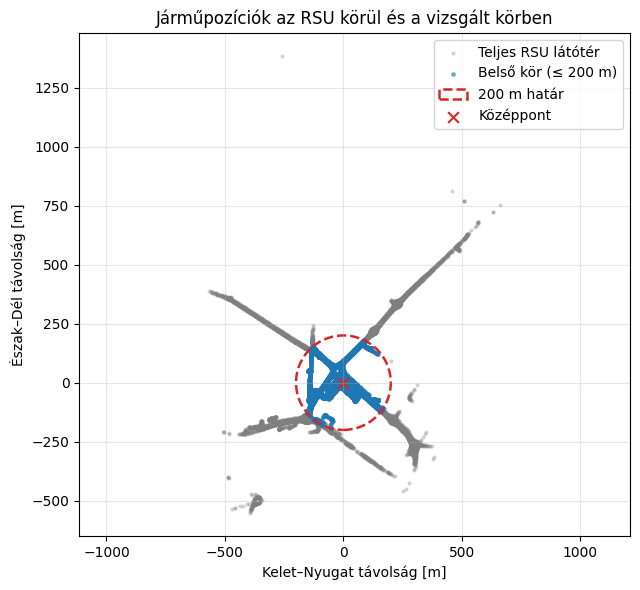

In [70]:
#Ábrázolás: nem kell rajta semmit változtatni

# Egyszerű 2D-s térbeli ábra: teljes RSU látótér vs. R_M méteres kör
fig, ax = plt.subplots(figsize=(6.5, 6.0))
ax.scatter(dx_m, dy_m, s=4, alpha=0.25, color="tab:gray", label="Teljes RSU látótér")
ax.scatter(
    dx_m[df["dist_m"] <= R_M],
    dy_m[df["dist_m"] <= R_M],
    s=6,
    alpha=0.5,
    color="tab:blue",
    label=f"Belső kör (≤ {R_M:.0f} m)",
)
circle_patch = plt.Circle((0, 0), R_M, color="tab:red", fill=False, lw=1.8, ls="--", label=f"{R_M:.0f} m határ")
ax.add_patch(circle_patch)
ax.scatter([0], [0], color="tab:red", marker="x", s=60, label="Középpont")
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("Kelet–Nyugat távolság [m]")
ax.set_ylabel("Észak–Dél távolság [m]")
ax.set_title("Járműpozíciók az RSU körül és a vizsgált körben")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Az ábra igen látványos, azonban a fentebbi megjegyzésemből kiderül, hogy azon adat ami kijelenti, hogy x autó van a környéken, hamis. Ez arra alapul, hogy egy autóhoz, egy stationID tartozik, ami a valóságban nem így van.

Az ETSI adatvédelmi mechanizmusa szerint a járművek időnként új `stationID`-t és MAC-címet vesznek fel, hogy a RSU  ne követhesse őket hosszú ideig. Ezért az előző feladat felülbecsli a valódi járműszámot. A CAMASA szerzői ezt (a feldolgozó láncuk 6. lépésében) heurisztikával összekapcsolják.

 **Két azonosító ugyanahhoz az autóhoz tartozik, ha:**

  >az egyik utolsó üzenete és a másik első üzenete között **≤ 1,5 s** telt el **ÉS**
  
  > a **távolság ≤ 21 m**.


###**Feladat**

Egészítsd ki a reconcile függvényt, a fentebbi megfelelő logikával, hogy a tényleges adatot is meg tudjuk vizsgálni.

> Megjegyzés: Ha több jelölt is megfelel, válaszd a térben legközelebbit, és minden jelöltet legfeljebb egyszer használj fel.

In [66]:
def reconcile(df_in, max_gap=1.5, max_dist=21.0):
    c = df_in.dropna(subset=["lat", "lon"]).sort_values("timestamp").copy()
    lat_ref = c["lat"].mean()
    c["x"] = c["lon"] * 111320.0 * np.cos(np.radians(lat_ref))
    c["y"] = c["lat"] * 110574.0

    # Minden stationID-hez az első és utolsó észlelés ideje és helye
    info = (
        c.groupby("stationID")
        .agg(
            t_first=("rel_time", "min"),
            t_last=("rel_time", "max"),
            x_first=("x", "first"),
            y_first=("y", "first"),
            x_last=("x", "last"),
            y_last=("y", "last"),
        )
        .sort_values("t_first")
        .reset_index()
    )

    chain = list(range(len(info)))
    used = set()

    for i in range(len(info)):
        # TODO 1: Időbeli és térbeli távolság az új azonosító kezdete és a korábbiak vége között
        dt = info.loc[i, "t_first"] - info["t_last"]
        dist = np.hypot(
            info.loc[i, "x_first"] - info["x_last"],
            info.loc[i, "y_first"] - info["y_last"],
        )

        # TODO 2: Jelöltek szűrése (max_gap időn és max_dist távolságon belül, még nem felhasznált)
        candidates = info[
            (dt > 0) & (dt <= max_gap) & (dist <= max_dist) & (~info.index.isin(used))
        ]

        if not candidates.empty:
            # TODO 3: A térben legközelebbi előd kiválasztása
            best_j = dist.loc[candidates.index].idxmin()
            chain[i] = chain[best_j]
            used.add(best_j)

    return pd.Series(chain, index=info["stationID"])


# Összekapcsolás a teljes adathalmazon és a körön belül
chain_all = reconcile(df)
df["veh_chain"] = df["stationID"].map(chain_all)

veh_total = df["veh_chain"].nunique()
veh_circle = df[df["dist_m"] <= R_M]["veh_chain"].nunique()

print("\n--- Álnévváltások összekapcsolása után ---")
print(f"Teljes RSU látótér: {total_ids} stationID  ->  {veh_total} becsült valódi jármű ({1 - veh_total / total_ids:.1%}-kal kevesebb)")
print(f"{R_M:.0f} m-es körön belül: {circle_ids} stationID  ->  {veh_circle} becsült valódi jármű ({1 - veh_circle / circle_ids:.1%}-kal kevesebb)")


--- Álnévváltások összekapcsolása után ---
Teljes RSU látótér: 104 stationID  ->  94 becsült valódi jármű (9.6%-kal kevesebb)
100 m-es körön belül: 35 stationID  ->  32 becsült valódi jármű (8.6%-kal kevesebb)


#**Mire való mindez a gyakorlatban?**

Forgalomfigyelésre és csatornaterhelés-tervezésre (hány RSU kell, mekkora a várható terhelés csúcsidőben), valamint digitális ikrek és forgalmi szimulátorok (pl. SUMO) kalibrálására – ezt a CAMASA szerzői is célként jelölik meg.

#**🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓🚗🚓**

## **Kitekintés**

**GeoNetworking.** A szemfülesebbek már észrevehették, hogy a CAM-ok *földrajzi* koordinátákat (és nem IP-címeket) hordoznak, és a `source_address` oszlop is egy MAC-szerű cím. A V2X-ben (ITS-G5) a hálózati réteg a **GeoNetworking** protokoll: a csomagok címzése és továbbítása **földrajzi helyen alapul** („küldd mindenkinek a körzetben"), nem IP-útválasztáson – a járművek folyamatosan változó topológiájú ad-hoc hálózatában ez a természetes megközelítés. A CAM-ok szóró (*single-hop broadcast*) csomagok, ezért nincs visszaigazolás (ACK) sem: **amit az útmenti egység nem hall meg, az végleg elveszett.**

##**Ötletek továbbfejlesztésre**
Ha esetleg izgalmas volt számodra a téma, én még gondoltam pár feladatra, amellyel  lehet vizsgálni a V2X-et forgalmát:

>**Építs egy NN-öt arra, hogy eldöntsd, egy adott időszak "rush hour" vagy "quiet".**

Röviden, hozz létre egy oszlopot ami a kimeneti, prediktálandó mező lesz, és az alapján alakíts ki egy Neurális Hálót, hogy minél jobban meg tudja tippelni, egy tesztadaton, hogy az adott időbeli adatgyűjtés forgalmas vagy csendes időszakban történt-e. Binning hasznos lehet.

>**Támadások/anomáliák detektálása**

Hirtelen kiugró adatok, egyes autók valamilyen pozíciót küldenek magukról amely lehetetlen, és ezek vizsgálata. A támadásos feladathoz, ha más adathalmazt szeretnél használni, akkor pl. a VeReMi adathalmaz támadásokra van kiélezve, én is azzal kezdtem ezt a labort, majd tértem át egy "kezdőbarátabb" adathalmazra.

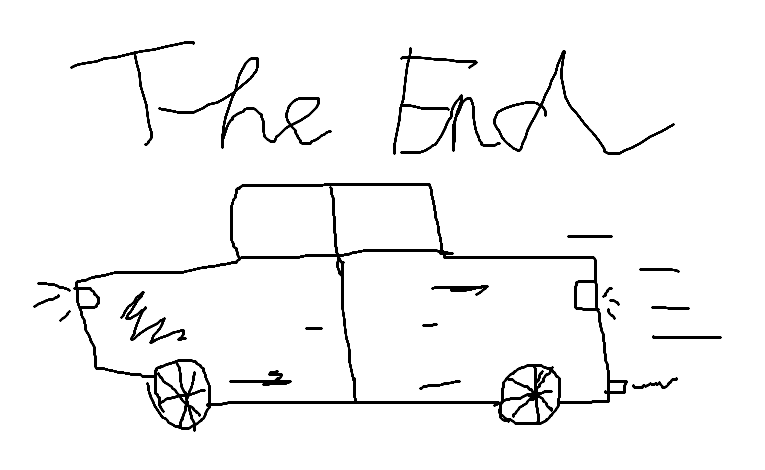

**Adatforrás:** a feladatsor adatai a *CAMASA* adathalmazból (Iandolo és mtsai, 2026) származnak: 10 nyers PCAP-fájl egyetlen RSU-ról, a szerzők hivatalos feldolgozó scriptjeivel (`camasa-dataset-filtering`) feldolgozva és összefűzve.



**Hivatkozás:**
```bibtex
@misc{iandolo2026camasa,
  title         = {CAMASA: A CAM-based Dataset from the MASA Living Lab},
  author        = {Iandolo, Salvatore and Savarese, Marco and Cauchi, Gaetano Orazio and Solida, Antonio and Klapez, Martin and Casoni, Maurizio and Porrello, Angelo and Grazia, Carlo Augusto},
  year          = {2026},
  eprint        = {2606.10641},
  archivePrefix = {arXiv},
  primaryClass  = {cs.NI},
  note          = {Accepted at IEEE VTC2026-Fall}
}
```
https://arxiv.org/abs/2606.10641